In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import warnings
warnings.filterwarnings("ignore")

# Q1: Load the penguins dataset from seaborn into a
# DataFrame named df and display the first 5 rows

df = sns.load_dataset("penguins")
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


In [8]:
# Q2: Print the following:

print(df.shape)
print("\n")
print(df.columns)
print("\n")
print(df.dtypes)

(344, 7)


Index(['species', 'island', 'bill_length_mm', 'bill_depth_mm',
       'flipper_length_mm', 'body_mass_g', 'sex'],
      dtype='object')


species               object
island                object
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                   object
dtype: object


In [10]:
# Q3: Check for missing values in each column:

df.isna().sum()

species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

In [ ]:
# Q4: Create a cleaned copy called df_clean by:

# 1) Drop duplicates
df_clean = df.copy()
df_clean.drop_duplicates(inplace = True)

# 2) Fill missing values

categorical = df_clean.select_dtypes(include = "object").columns
numerical = df_clean.select_dtypes(exclude = "object").columns

for category in categorical:
    Mode = df_clean[category].mode()
    df_clean[category].fillna(Mode, inplace = True)

for numeric in numerical:
    Median = df_clean[numeric].median()
    df_clean[numeric].fillna(Median, inplace = True)
    
# Verify

df_clean.isna().sum()

species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  0
dtype: int64

In [50]:
# Q5: Filter the dataset to include only penguins from the island "Biscoe" 

biscoe_df = df_clean[df_clean["island"]=="Biscoe"]
biscoe_df.shape

(168, 7)

In [54]:
# Q6: Find all penguins with:

overall_mean = df_clean["body_mass_g"].mean()
heavy_males = (df["body_mass_g"]>overall_mean) & (df["sex"] == "Male")

In [56]:
# Q7: Sort df_clean by:

df_clean.sort_values(by = ["body_mass_g", "bill_length_mm"], ascending = [False, True]).head(10)

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
237,Gentoo,Biscoe,49.2,15.2,221.0,6300.0,Male
253,Gentoo,Biscoe,59.6,17.0,230.0,6050.0,Male
337,Gentoo,Biscoe,48.8,16.2,222.0,6000.0,Male
297,Gentoo,Biscoe,51.1,16.3,220.0,6000.0,Male
299,Gentoo,Biscoe,45.2,16.4,223.0,5950.0,Male
331,Gentoo,Biscoe,49.8,15.9,229.0,5950.0,Male
233,Gentoo,Biscoe,48.4,14.6,213.0,5850.0,Male
235,Gentoo,Biscoe,49.3,15.7,217.0,5850.0,Male
335,Gentoo,Biscoe,55.1,16.0,230.0,5850.0,Male
295,Gentoo,Biscoe,48.6,16.0,230.0,5800.0,Male


In [64]:
# Q8: Compute the following aggregations:

# 1) Mean body mass per species
df_clean.groupby("species")["body_mass_g"].mean().sort_values(ascending = False)

# 2) Mean bill length per (species, sex)
df_clean.groupby(["species", "sex"])["bill_length_mm"].mean()


# 3) Count per island
df_clean["island"].value_counts()


island
Biscoe       168
Dream        124
Torgersen     52
Name: count, dtype: int64

In [96]:
# Q9: Feature engineering:

#1) Add it to `df_clean`
df_clean["bill_ratio"] = df_clean["bill_length_mm"]/df_clean["bill_depth_mm"]

#2) Show summary statistics for `bill_ratio`
df_clean["bill_ratio"].describe()

#3) Identify which species has the **highest average bill_ratio**
highest_avg = df_clean["bill_ratio"].mean()
highest_avg
df_clean.loc[df_clean["bill_ratio"].idxmax(), "species"]

'Gentoo'

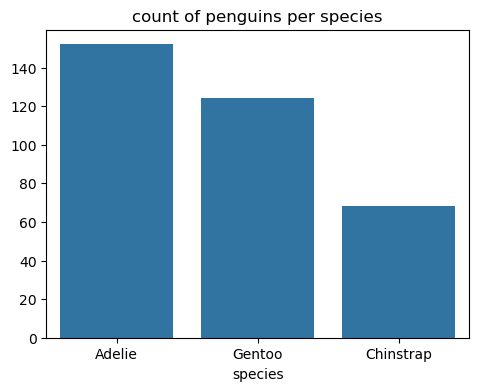

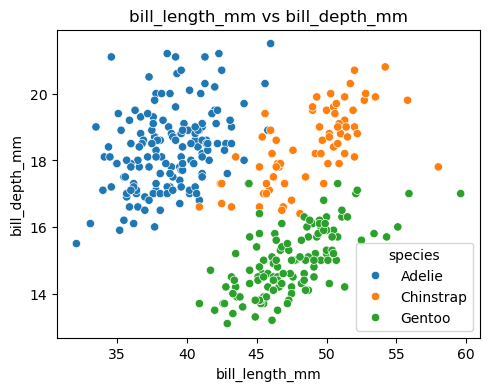

In [126]:
# Q10: Create the following plots using df_clean :

plt.figure(figsize = (12, 4))

# 1) Count per species (bar)
plt.subplot(1,2,1)
counts = df_clean["species"].value_counts()
sns.barplot(x = counts.index, y = counts.values)
plt.xlabel = "index"
plt.ylabel = "value"
plt.title("count of penguins per species")
plt.show()

plt.figure(figsize = (12, 4))
# 2) Scatter: bill length vs bill depth (color by species)
plt.subplot(1,2,2)
sns.scatterplot(data = df_clean, x = "bill_length_mm", y = "bill_depth_mm", hue = "species")
plt.xlabel = "bill_length_mm"
plt.ylabel = "bill_depth_mm"
plt.title("bill_length_mm vs bill_depth_mm")
plt.show()


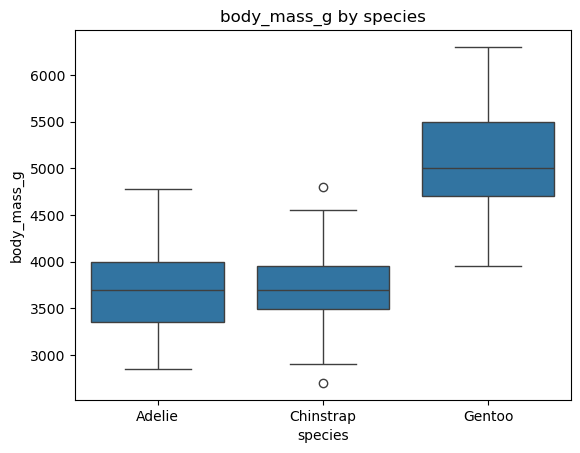

In [129]:
# Q11: Create a box plot of body_mass_g by species.

sns.boxplot( data = df_clean, x = "species", y = "body_mass_g")
plt.title("body_mass_g by species")
plt.show()

In [ ]:
# The Gentoo has the highest median mass, as its box is positioned higher than the other 2 species
# higher median -> higher body mass
# The Chinstrap has 2 points at the top and bottom which represent outliers
# So, Chinstrap has 2 outliers

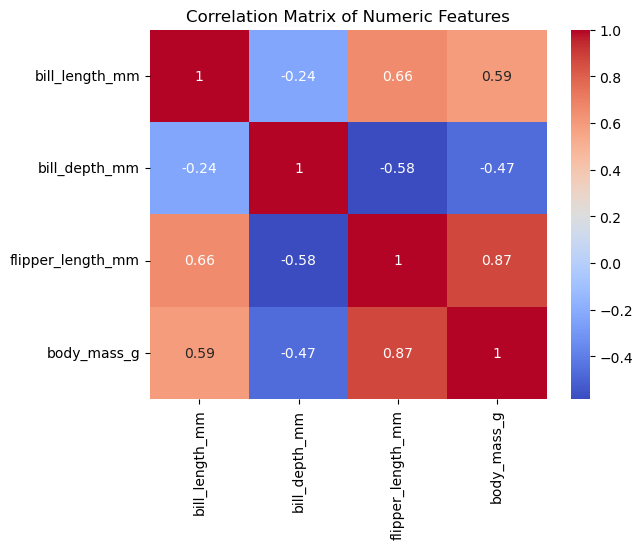

In [137]:
# Q12: Compute a correlation matrix for numeric features and visualize it as a heatmap.

corr_matrix = df_clean[numerical].corr()
sns.heatmap(data = corr_matrix, cmap = "coolwarm", annot = True)
plt.title("Correlation Matrix of Numeric Features")
plt.show()

In [143]:
# Q13: Define

y = df_clean["species"]
X = df_clean.drop(columns = ["species"])

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    stratify = y,
    test_size = 0.2,
    random_state = 42
)

In [161]:
# Q14: Preprocessing Data for ML Training

# Identify columns by type

numeric_features = X.select_dtypes(exclude = "object").columns
categoric_features = X.select_dtypes(include = "object").columns

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy = "median")),
    ("scaler", StandardScaler())
])
categorical_transformer = Pipeline(steps=[
 ("imputer", SimpleImputer(strategy="most_frequent")),
 ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocess = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features),
])


In [164]:
# Q15: Train models:

# 1) KNN pipeline
knn_model = Pipeline(steps=[
 ("preprocess", preprocess),
 ("model", KNeighborsClassifier(n_neighbors=5))
])

#Train the model using the fit method
knn_model.fit(X_train, y_train)

# Predict on the X_test
y_pred = knn_model.predict(X_test)
print(y_pred)

#calculate and print the accuracy based on the prediction of the X_test
acc = accuracy_score(y_test, y_pred)
print(acc)

['Adelie' 'Adelie' 'Gentoo' 'Gentoo' 'Chinstrap' 'Adelie' 'Chinstrap'
 'Gentoo' 'Chinstrap' 'Chinstrap' 'Adelie' 'Gentoo' 'Chinstrap' 'Gentoo'
 'Gentoo' 'Gentoo' 'Adelie' 'Adelie' 'Gentoo' 'Gentoo' 'Chinstrap'
 'Gentoo' 'Gentoo' 'Adelie' 'Adelie' 'Adelie' 'Gentoo' 'Adelie' 'Gentoo'
 'Gentoo' 'Adelie' 'Adelie' 'Adelie' 'Adelie' 'Adelie' 'Gentoo' 'Gentoo'
 'Adelie' 'Adelie' 'Gentoo' 'Chinstrap' 'Chinstrap' 'Adelie' 'Chinstrap'
 'Adelie' 'Chinstrap' 'Adelie' 'Adelie' 'Adelie' 'Gentoo' 'Adelie'
 'Adelie' 'Chinstrap' 'Adelie' 'Gentoo' 'Chinstrap' 'Adelie' 'Chinstrap'
 'Adelie' 'Gentoo' 'Gentoo' 'Chinstrap' 'Gentoo' 'Gentoo' 'Chinstrap'
 'Gentoo' 'Adelie' 'Adelie' 'Gentoo']
0.9855072463768116


In [165]:
# 2) Logistic Regression pipeline
logreg_model = Pipeline(steps=[
 ("preprocess", preprocess),
 ("model", LogisticRegression(max_iter=2000))
])

# Train the model using the fit method
logreg_model.fit(X_train, y_train)

# Predict on the X_test
y_pred = logreg_model.predict(X_test)
print(y_pred)

#calculate and print the accuracy based on the prediction of the X_test
acc = accuracy_score(y_test, y_pred)
print(acc)

['Adelie' 'Adelie' 'Gentoo' 'Gentoo' 'Chinstrap' 'Adelie' 'Chinstrap'
 'Gentoo' 'Chinstrap' 'Chinstrap' 'Adelie' 'Gentoo' 'Chinstrap' 'Gentoo'
 'Gentoo' 'Gentoo' 'Adelie' 'Adelie' 'Gentoo' 'Gentoo' 'Chinstrap'
 'Gentoo' 'Gentoo' 'Adelie' 'Adelie' 'Adelie' 'Gentoo' 'Adelie' 'Gentoo'
 'Gentoo' 'Adelie' 'Adelie' 'Adelie' 'Adelie' 'Adelie' 'Gentoo' 'Gentoo'
 'Adelie' 'Adelie' 'Gentoo' 'Chinstrap' 'Adelie' 'Adelie' 'Chinstrap'
 'Adelie' 'Chinstrap' 'Adelie' 'Adelie' 'Adelie' 'Gentoo' 'Adelie'
 'Adelie' 'Chinstrap' 'Adelie' 'Gentoo' 'Chinstrap' 'Adelie' 'Chinstrap'
 'Adelie' 'Gentoo' 'Gentoo' 'Chinstrap' 'Gentoo' 'Gentoo' 'Chinstrap'
 'Gentoo' 'Adelie' 'Adelie' 'Gentoo']
1.0


Logistic Regression achieved a slightly higher accuracy (1.00) compared to KNN (0.9855).

Therefore, on this dataset, Logistic Regression performs marginally better.

However, the difference is small,and both models demonstrate very high performance.